In [82]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [83]:
# load the csv
df = pd.read_csv("data/battery_data.csv")

arr = df.to_numpy()
hours_arr = arr[:,0].astype(float)
life_arr = arr[:,1].astype(float)
drained_arr = life_arr[0] - life_arr

<function matplotlib.pyplot.show(close=None, block=None)>

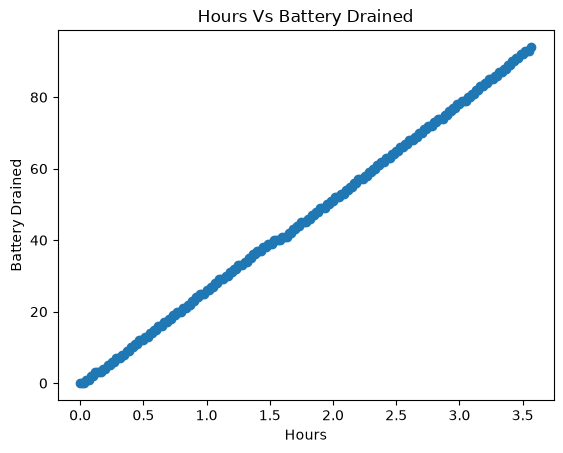

In [84]:
plt.scatter(hours_arr, drained_arr)
plt.title("Hours Vs Battery Drained")
plt.xlabel("Hours")
plt.ylabel("Battery Drained")
plt.show

In [85]:
# cost calculation

def cost(x_i: np.ndarray, y_i: np.ndarray, w: float, b: float) -> float:    
    f_wb = w * x_i + b
    sum = (f_wb - y_i) ** 2
    sum = np.sum(sum)
    cost = sum / (2 * len(x_i))
    return cost

In [86]:
def gradient(x_i: np.ndarray, y_i: np.ndarray, w: float, b: float) -> tuple:
    f_wb = w * x_i + b
    sum_b = f_wb - y_i
    sum_w = sum_b * x_i
    sum_w = np.sum(sum_w)
    sum_b = np.sum(sum_b)

    grad_w = sum_w / (len(x_i))
    grad_b = sum_b / (len(x_i))
    return grad_w, grad_b

In [87]:
# change w and b simultaneously until we done

def lin_regression(x_i: np.ndarray, y_i: np.ndarray, alpha: float, cost, gradient) -> tuple:
    costs = []
    parameters = []
    w = 0
    b = 0
    prev_cost = 0
    curr_cost = cost(x_i, y_i, w, b)
    iters = 0
    while (abs(prev_cost - curr_cost) > 0.0000001):
        prev_cost = curr_cost
        grad_w, grad_b = gradient(x_i, y_i, w, b)
        w = w - alpha * grad_w
        b = b - alpha * grad_b
        curr_cost = cost(x_i, y_i, w, b)
        costs.append(curr_cost)
        parameters.append([w, b])
        if iters % 50 == 0:
            print(f"iter: {iters} w: {w} b: {b} cost: {curr_cost}")
        iters += 1            
    return w, b, costs, parameters

In [88]:
w_final, b_final, costs, parameters = lin_regression(hours_arr, drained_arr, 0.1, cost, gradient)
print(w_final, b_final)

iter: 0 w: 11.040829622111795 b: 4.613023255813953 cost: 362.90700645571235
iter: 50 w: 24.76772686011702 b: 2.696751279345001 cost: 1.6548675573360918
iter: 100 w: 25.775690991952224 b: 0.414437351919124 cost: 0.3070940038895714
iter: 150 w: 26.12026043366887 b: -0.36576465225679655 cost: 0.14959410023849803
iter: 200 w: 26.238050438704814 b: -0.6324743103828645 cost: 0.13118876828442944
iter: 250 w: 26.278316590042106 b: -0.7236481876056693 cost: 0.12903793367128702
iter: 300 w: 26.292081450167743 b: -0.7548156974223234 cost: 0.12878658859668357
iter: 350 w: 26.29678692531214 b: -0.7654702148977299 cost: 0.12875721658167952
26.297382103019864 -0.7668178644109609


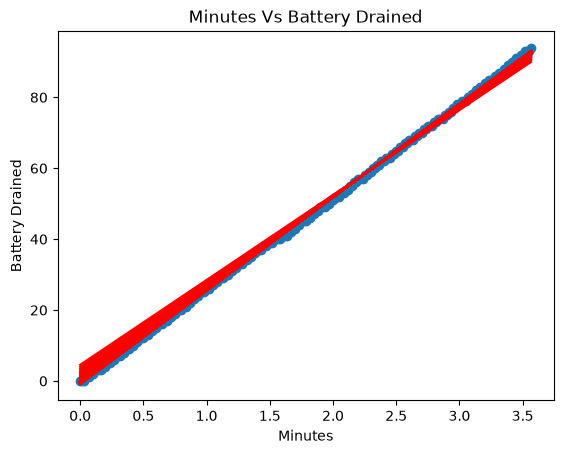

In [89]:
plt.scatter(hours_arr, drained_arr)
for i in range(30, len(parameters), 5):
    plt.plot(hours_arr, parameters[i][0]*hours_arr + parameters[i][1], color="red", label="model")
plt.title("Minutes Vs Battery Drained")
plt.xlabel("Minutes")
plt.ylabel("Battery Drained")
plt.show()

In [91]:
test_df = pd.read_csv("data/test_data.csv")

test_arr = test_df.to_numpy()
test_hours = test_arr[:,0].astype(float)
test_life = test_arr[:,1].astype(float)
test_drained = test_life[0] - test_life


pred_drained = w_final * test_hours + b_final

mae = np.sum(abs(test_drained - pred_drained)) / test_life.shape[0]

print(mae)

0.7258096398414992
